
# 9. 스테레오 비전 (Stereo Vision)

- **서로 다른 시점에서 본 두 영상**의 위치 차이로 깊이를 추정하는 방법이다.
- 첨부된 첫 번째 영상을 `assets/tsukuba_l.png`, 두 번째 영상을 `assets/tsukuba_r.png`로 사용한다. 두 파일은 모두 384×288이며 원본 픽셀을 유지했다.
- 한 장을 단순히 이동시켜 만든 입력이 아니라, 첨부된 Tsukuba 좌우 영상의 대응 관계를 계산한다.
- 이 자료는 **시차 맵 → 좌우 일관성 검사 → 상대 깊이 지표**까지 실제 계산한다.
- 제공된 두 PNG에는 초점거리·베이스라인·보정 행렬과 정답 시차 맵이 포함되어 있지 않다. 미터 단위 깊이나 정답 대비 정확도를 만들어 내지 않는다.

## 9.1 두 카메라와 깊이의 관계

### 같은 물체가 좌우에서 다른 위치에 보인다

- 한쪽 눈씩 번갈아 감으면 가까운 손가락이 더 많이 움직여 보인다.
- 수평 스테레오 영상도 같은 점이 왼쪽의 $x_L$, 오른쪽의 $x_R$에 나타나는 차이를 측정한다.
- 이 가로 위치 차이를 **시차(disparity)**라고 한다.

$$d=x_L-x_R$$

정렬된 두 카메라의 주점 x좌표가 같고, 오른쪽 카메라가 왼쪽 카메라의 오른편에 있는 수평 구성에서는:

$$Z=\frac{fB}{d}$$

| 기호 | 뜻 | 단위 |
| :---: | :---: | :---: |
| $d$ | 왼쪽 위치 − 오른쪽 대응 위치 | 픽셀 |
| $f$ | 정렬 후 초점거리 | 픽셀 |
| $B$ | 두 카메라의 광학 중심 사이 거리 | m 등 길이 |
| $Z$ | 정렬된 카메라의 광축 방향 깊이 | $B$와 같은 단위 |

- 같은 카메라 조건에서 **시차가 크면 가깝고, 시차가 작으면 멀다.**
- $Z$는 카메라에서 점까지의 직선거리 $\sqrt{X^2+Y^2+Z^2}$와 구분한다.
- 주점 차이가 있으면 $d$에서 그 차이를 빼야 한다. 9.5에서 다시 설명한다.

### 셀 1. Tsukuba 좌우 영상 읽기

- 이미지 크기와 자료형이 같은지 확인한다.
- 입력 PNG는 RGB 형식이지만 세 채널의 값이 같다. 시차 계산에는 8비트 그레이스케일을 사용한다.
- 가로 안내선은 대응점의 높이를 비교하기 위한 표시이며, 영상 정렬을 수행하는 연산은 아니다.

입력 크기: 384 × 288, OpenCV: 5.0.0


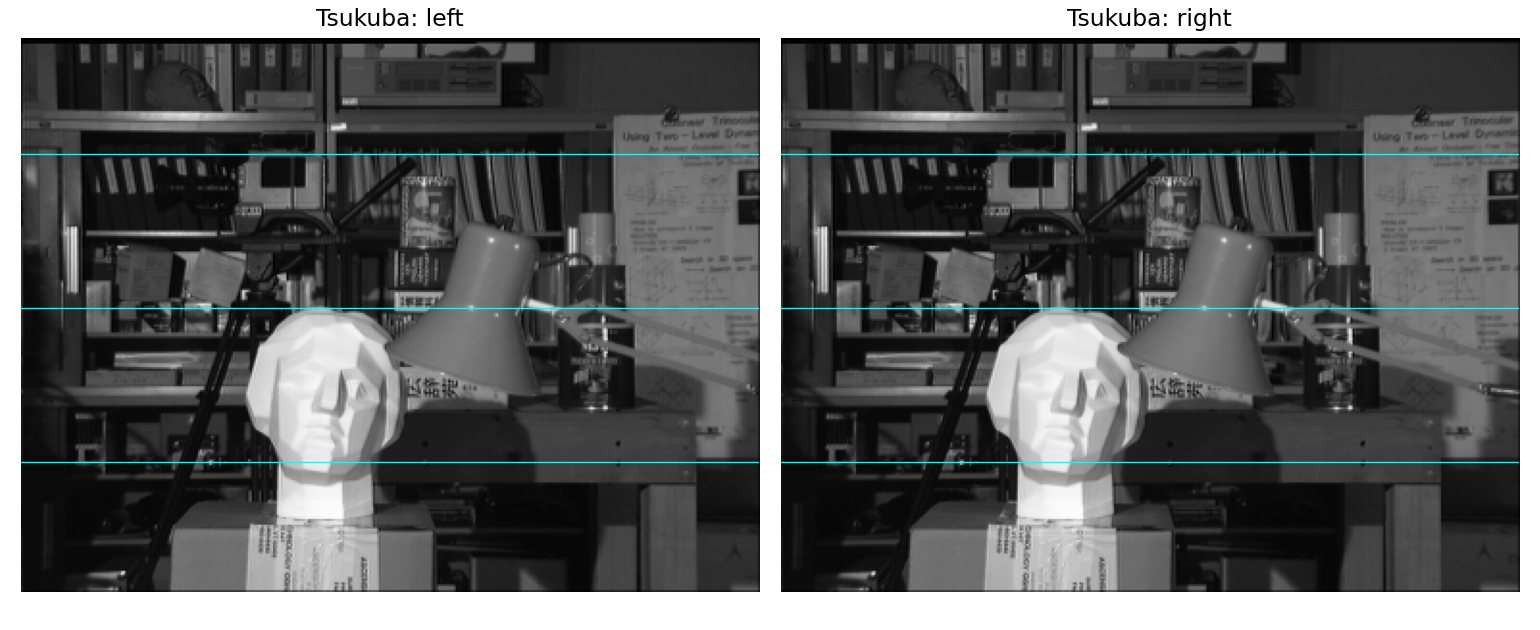

In [1]:
# 셀 1: 첨부된 좌우 영상을 읽고 같은 높이의 안내선을 표시한다.
from pathlib import Path
import csv
import hashlib
import json
import platform
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

# Python 파일은 파일 위치, 노트북은 현재 작업 폴더에서 assets를 찾는다.
ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
ASSETS = ROOT / 'assets'
cv2.setNumThreads(1)
cv2.setRNGSeed(42)

def read_gray(name):
    # 한글 경로도 읽을 수 있도록 파일 바이트를 OpenCV로 디코딩한다.
    path = ASSETS / name
    if not path.is_file():
        raise FileNotFoundError(f'입력 파일을 찾을 수 없습니다: {path}')
    image = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f'이미지 디코딩 실패: {path}')
    return image

left = read_gray('tsukuba_l.png')
right = read_gray('tsukuba_r.png')
assert left.shape == right.shape and left.dtype == right.dtype == np.uint8
height, width = left.shape
print(f'입력 크기: {width} × {height}, OpenCV: {cv2.__version__}')

def finish(fig, name):
    # 같은 그림을 MD용 PNG와 노트북 출력으로 사용한다.
    fig.tight_layout()
    path = ASSETS / name
    fig.savefig(path, dpi=140, facecolor='white')
    plt.close(fig)
    display(Image(filename=str(path)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, image, title in zip(axes, [left, right], ['Tsukuba: left', 'Tsukuba: right']):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    for y in [60, 140, 220]:
        ax.axhline(y, color='cyan', linewidth=0.7)
    ax.set_title(title)
    ax.axis('off')
finish(fig, '01_stereo_pair.png')

## 9.2 카메라 보정

### 카메라의 숫자 정보를 알아내기

- **내부 파라미터**: 초점거리 $f_x,f_y$, 주점 $c_x,c_y$다.
- **왜곡 계수**: 렌즈로 인해 영상이 휘는 현상을 모델링한다.
- **외부 파라미터**: 왼쪽 카메라 좌표를 오른쪽 카메라 좌표로 바꾸는 회전 $R$과 이동 $T$다.

$$K=\begin{bmatrix}f_x&0&c_x\\0&f_y&c_y\\0&0&1\end{bmatrix}$$

$$\mathbf X_R=R\mathbf X_L+T,\qquad B=\lVert T\rVert$$

- 실제 보정에서는 칸 크기를 아는 체커보드를 여러 위치와 기울기에서 좌우 카메라로 촬영한다.
- `findChessboardCorners()`와 `cornerSubPix()`로 같은 실제 모서리의 좌우 좌표를 구한다.
- `calibrateCamera()`로 각 카메라의 내부 파라미터와 왜곡을, `stereoCalibrate()`로 좌우 관계를 구한다.
- 보드 좌표의 길이 단위가 m이면 $T$도 m 단위가 된다.
- 해상도·크롭·초점 설정을 바꾸면 보정값과 영상 좌표의 관계도 다시 확인한다.

### 셀 2. 보정 관측값이 있을 때 사용하는 함수

**이번 첨부 파일에는 체커보드 관측값이 없으므로 아래 함수는 정의만 한다.** Tsukuba 장면의 물체 모서리를 체커보드의 알려진 3차원 좌표처럼 사용하지 않는다. 최소 3쌍 검사는 너무 적은 입력을 막는 조건이며 보정 정확도를 보장하는 기준은 아니다.

In [2]:
# 셀 2: 실제 체커보드 관측값으로 보정하는 함수이며, 이번 영상에는 호출하지 않는다.
def calibrate_pair(object_points, left_points, right_points, image_size):
    # object_points: 보드 위 3차원 점, left/right_points: 같은 점의 좌우 영상 좌표.
    count = len(object_points)
    if not (count == len(left_points) == len(right_points)) or count < 3:
        raise ValueError('서로 대응하는 여러 자세의 좌우 보정 관측이 필요합니다.')

    # OpenCV가 요구하는 float32 배열과 점 모양으로 맞춘다.
    obj = [np.asarray(p, np.float32).reshape(-1, 3) for p in object_points]
    pts_l = [np.asarray(p, np.float32).reshape(-1, 1, 2) for p in left_points]
    pts_r = [np.asarray(p, np.float32).reshape(-1, 1, 2) for p in right_points]
    for p3, pl, pr in zip(obj, pts_l, pts_r):
        if not (len(p3) == len(pl) == len(pr)):
            raise ValueError('한 관측 안의 3차원 점과 좌우 점 개수가 다릅니다.')

    # 각 카메라의 내부 행렬 K와 렌즈 왜곡 D를 추정한다.
    rms_l, K_l, D_l, _, _ = cv2.calibrateCamera(obj, pts_l, image_size, None, None)
    rms_r, K_r, D_r, _, _ = cv2.calibrateCamera(obj, pts_r, image_size, None, None)
    # 내부 파라미터를 고정하고 왼쪽→오른쪽 회전과 이동을 추정한다.
    rms, K_l, D_l, K_r, D_r, R, T, E, F = cv2.stereoCalibrate(
        obj, pts_l, pts_r, K_l, D_l, K_r, D_r, image_size,
        flags=cv2.CALIB_FIX_INTRINSIC)
    return dict(K_l=K_l, D_l=D_l, K_r=K_r, D_r=D_r, R=R, T=T,
                rms_left=rms_l, rms_right=rms_r, rms_stereo=rms, E=E, F=F)

print('보정 함수 정의 완료. 실제 보정 실행: 없음 — 체커보드 관측값 미제공')

보정 함수 정의 완료. 실제 보정 실행: 없음 — 체커보드 관측값 미제공


## 9.3 스테레오 정렬 (Rectification)

### 같은 점을 같은 행에서 찾도록 바꾸기

- 수평 스테레오에서는 같은 3차원 점이 좌우 영상의 같은 행에 나타나도록 재투영한다.
- 좌우의 x좌표까지 같게 만드는 작업은 아니다. 남아 있는 가로 차이가 시차다.
- 보정값을 아는 경우 `stereoRectify()` → `initUndistortRectifyMap()` → `remap()` 순서로 처리한다.
- 정렬에서 얻은 $P_L,P_R$은 새 투영행렬이고, $Q$는 시차를 3차원으로 재투영할 때 사용한다.
- 일반 입체 장면을 하나의 호모그래피로 완전히 겹치게 만드는 스티칭과 구분한다.

### 셀 3. 보정값이 있는 경우의 정렬 함수

이 실습은 첨부된 Tsukuba 쌍을 **수평 정렬된 입력으로 가정**하고 사용한다. 이 가정이 관측된 대응점과 맞는지 다음 셀에서 점검한다. 실제 보정값이 없으므로 임의의 $K,R,T$로 `stereoRectify()`를 실행하거나 가짜 $Q$를 만들지 않는다.

In [3]:
# 셀 3: 보정값이 제공된 경우의 정렬 경로를 정의한다.
def rectify_with_calibration(image_l, image_r, calibration):
    # 현재 입력과 같은 해상도에 맞는 실제 보정값을 전달해야 한다.
    if image_l.shape[:2] != image_r.shape[:2]:
        raise ValueError('좌우 영상 크기가 다릅니다.')
    size = (image_l.shape[1], image_l.shape[0])
    c = calibration
    R_l, R_r, P_l, P_r, Q, roi_l, roi_r = cv2.stereoRectify(
        c['K_l'], c['D_l'], c['K_r'], c['D_r'], size, c['R'], c['T'],
        flags=cv2.CALIB_ZERO_DISPARITY, alpha=0)
    # 각 출력 픽셀이 원본의 어느 위치를 읽을지 좌표 맵을 만든다.
    map_l = cv2.initUndistortRectifyMap(c['K_l'], c['D_l'], R_l, P_l, size, cv2.CV_32FC1)
    map_r = cv2.initUndistortRectifyMap(c['K_r'], c['D_r'], R_r, P_r, size, cv2.CV_32FC1)
    rect_l = cv2.remap(image_l, *map_l, interpolation=cv2.INTER_LINEAR)
    rect_r = cv2.remap(image_r, *map_r, interpolation=cv2.INTER_LINEAR)
    return rect_l, rect_r, dict(P_l=P_l, P_r=P_r, Q=Q, roi_l=roi_l, roi_r=roi_r)

# 이번 입력은 정렬된 영상으로 가정해 원본 그대로 사용한다. 이 복사는 정렬 연산이 아니다.
rect_l = left.copy()
rect_r = right.copy()
print('현재 계산 경로: 제공된 Tsukuba 좌우 영상 그대로 사용')

현재 계산 경로: 제공된 Tsukuba 좌우 영상 그대로 사용


### 셀 4. 대응점의 높이 차이 점검

- ORB 기술자를 해밍 거리로 비교하고, 1등과 2등 후보의 거리 비율이 0.75보다 작으면 남긴다.
- 남긴 전체 후보에서 $x_L-x_R$와 $|y_L-y_R|$를 측정한다. 세로 오차로 미리 걸러 낸 뒤 정렬이 좋다고 주장하지 않는다.
- 세로 차이가 작으면 수평 탐색 가정과 맞는다는 **진단 근거**가 된다.
- 특징점 위치 오차와 잘못된 대응도 포함될 수 있다. 이 검사는 카메라 보정의 정확도나 모든 픽셀의 정렬을 인증하지 않는다.

$$\Delta y_i=|y_{L,i}-y_{R,i}|$$

{
  "ratio_test_matches": 686,
  "median_abs_vertical_error_px": 0.0,
  "p90_abs_vertical_error_px": 1.6104812622070312,
  "fraction_abs_vertical_error_le_1px": 0.8658892128279884,
  "median_horizontal_disparity_px": 6.9120025634765625,
  "fraction_positive_horizontal_disparity": 1.0
}


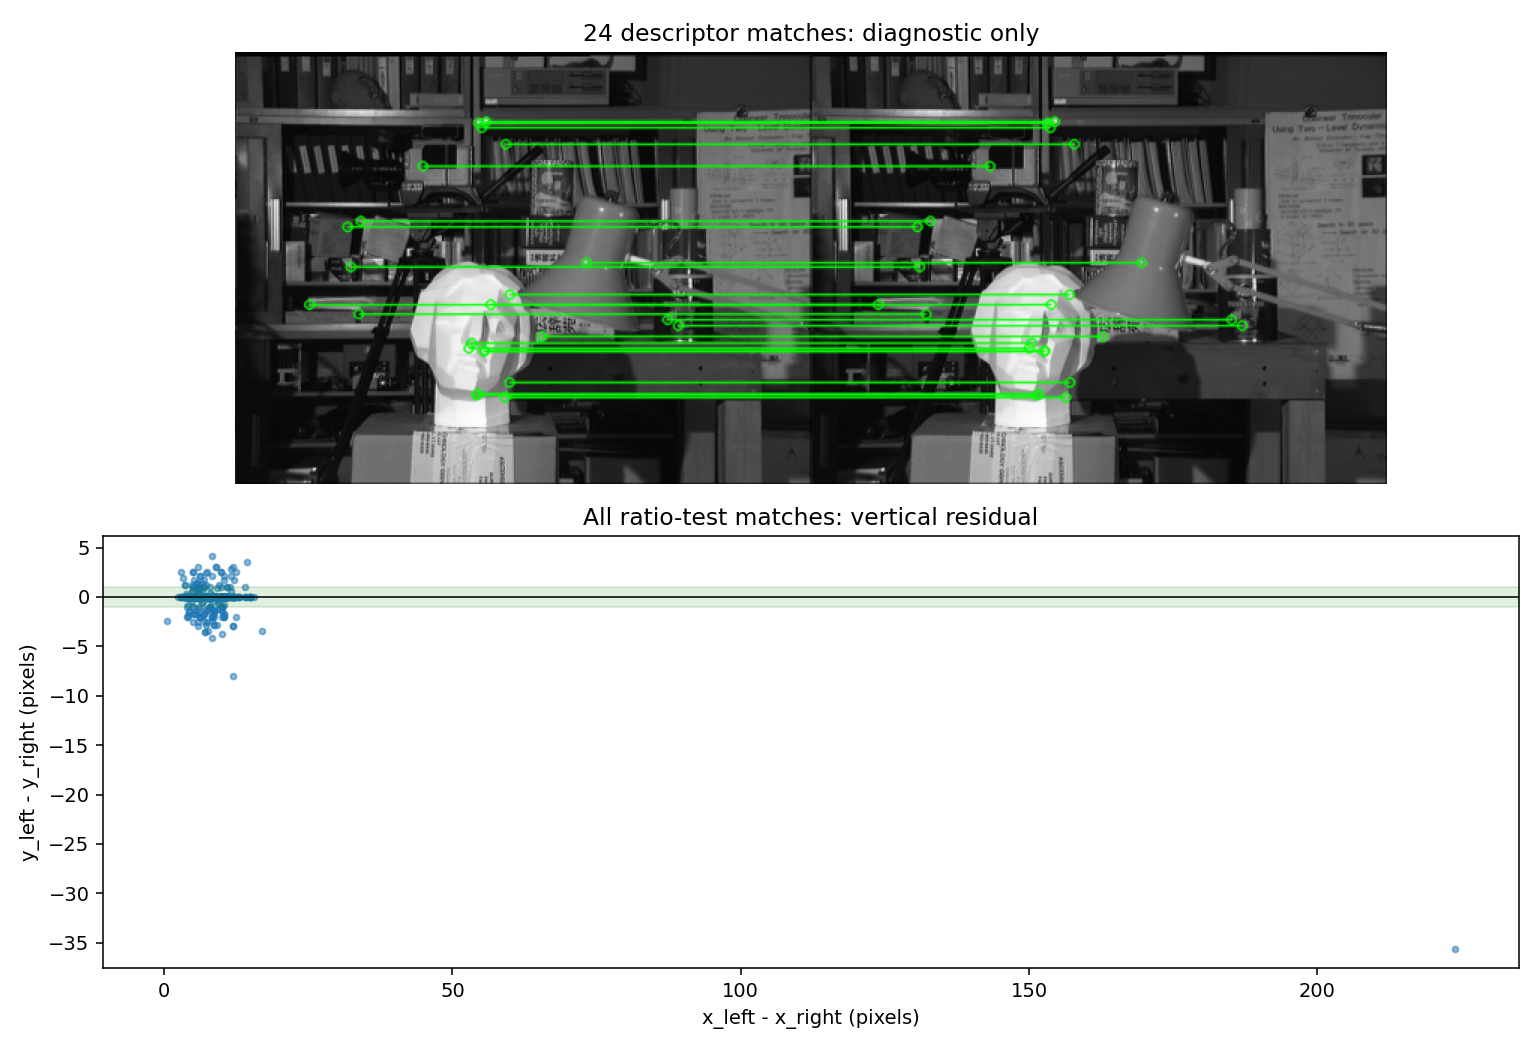

In [4]:
# 셀 4: 특징점 대응으로 수평 정렬 가정을 점검한다.
orb = cv2.ORB_create(nfeatures=1500, fastThreshold=10)
key_l, desc_l = orb.detectAndCompute(rect_l, None)
key_r, desc_r = orb.detectAndCompute(rect_r, None)
if desc_l is None or desc_r is None:
    raise RuntimeError('정렬 진단에 필요한 특징점을 찾지 못했습니다.')

# ORB 기본 이진 기술자는 해밍 거리를 사용한다.
pairs = cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(desc_l, desc_r, k=2)
good = []
for pair in pairs:
    if len(pair) == 2:
        first, second = pair
        if first.distance < 0.75 * second.distance:
            good.append(first)
if not good:
    raise RuntimeError('비율 검사를 통과한 대응점이 없습니다.')

points_l = np.float32([key_l[m.queryIdx].pt for m in good])
points_r = np.float32([key_r[m.trainIdx].pt for m in good])
dx = points_l[:, 0] - points_r[:, 0]
dy = points_l[:, 1] - points_r[:, 1]
alignment = {
    'ratio_test_matches': len(good),
    'median_abs_vertical_error_px': float(np.median(np.abs(dy))),
    'p90_abs_vertical_error_px': float(np.percentile(np.abs(dy), 90)),
    'fraction_abs_vertical_error_le_1px': float(np.mean(np.abs(dy) <= 1)),
    'median_horizontal_disparity_px': float(np.median(dx)),
    'fraction_positive_horizontal_disparity': float(np.mean(dx > 0)),
}
print(json.dumps(alignment, ensure_ascii=False, indent=2))

# 그림에는 거리 순 상위 24쌍만 표시하지만, 통계에는 모든 통과 후보를 사용했다.
selected = sorted(good, key=lambda m: m.distance)[:24]
matched = cv2.drawMatches(rect_l, key_l, rect_r, key_r, selected, None,
    matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
fig, axes = plt.subplots(2, 1, figsize=(11, 7.5))
axes[0].imshow(cv2.cvtColor(matched, cv2.COLOR_BGR2RGB))
axes[0].set_title('24 descriptor matches: diagnostic only')
axes[0].axis('off')
axes[1].scatter(dx, dy, s=9, alpha=0.5)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].axhspan(-1, 1, color='green', alpha=0.12)
axes[1].set(xlabel='x_left - x_right (pixels)', ylabel='y_left - y_right (pixels)',
            title='All ratio-test matches: vertical residual')
finish(fig, '02_alignment_check.png')

## 9.4 시차 맵 (Disparity Map)

### SGBM으로 픽셀별 가로 차이 계산하기

- SGBM은 대응 비용과 주변 시차의 매끄러움을 함께 고려한다.
- 비슷한 무늬가 여러 번 반복되거나, 무늬가 없거나, 한쪽에서만 보이는 영역에서는 틀릴 수 있다.
- 출력은 왼쪽 영상의 각 픽셀에 대응하는 시차다.

| 설정 | 이번 값 | 의미 |
| :---: | :---: | :---: |
| `minDisparity` | 0 | 탐색 시작 시차 |
| `numDisparities` | 32 | 탐색 범위의 폭, 양의 16의 배수 |
| `blockSize` | 5 | 비교 영역의 한 변, 1 이상의 홀수 |
| `P1`, `P2` | 200, 800 | 시차 변화의 벌점, `P2 > P1` |
| `uniquenessRatio` | 10 | 유일성 검사 설정, 정확도 90%라는 뜻은 아님 |
| `speckleWindowSize` | 50 | 작은 시차 영역 제거 설정 |
| `speckleRange` | 2 | 작은 영역 판정에서 허용할 시차 변화 |

여기서 `P1`, `P2`는 9.3의 투영행렬과 이름만 같다. SGBM에서는 이웃 간 1픽셀 시차 변화와 더 큰 변화에 대한 벌점이다. 이번 값은 단일 채널 기준 $P1=8\cdot5^2$, $P2=32\cdot5^2$로 정했다.

### 셀 5. 왼쪽 기준 시차 계산

OpenCV SGBM은 시차에 16을 곱한 고정소수점 정수 배열을 반환한다. 픽셀 단위로 해석하려면 다음 변환이 필요하다.

$$d_{\mathrm{pixel}}=\frac{d_{\mathrm{raw}}}{16}$$

- `minDisparity=0`일 때 대표적인 무효 출력은 원시 정수 −16, 즉 −1픽셀이다.
- 이번 깊이 비교에서는 시차 0도 제외한다. 0을 작은 양수로 바꿔 가짜 깊이를 만들지 않는다.
- 양의 시차만 남겼다고 올바른 대응이 보장되지는 않는다.

양의 시차를 가진 픽셀 비율: 89.23%


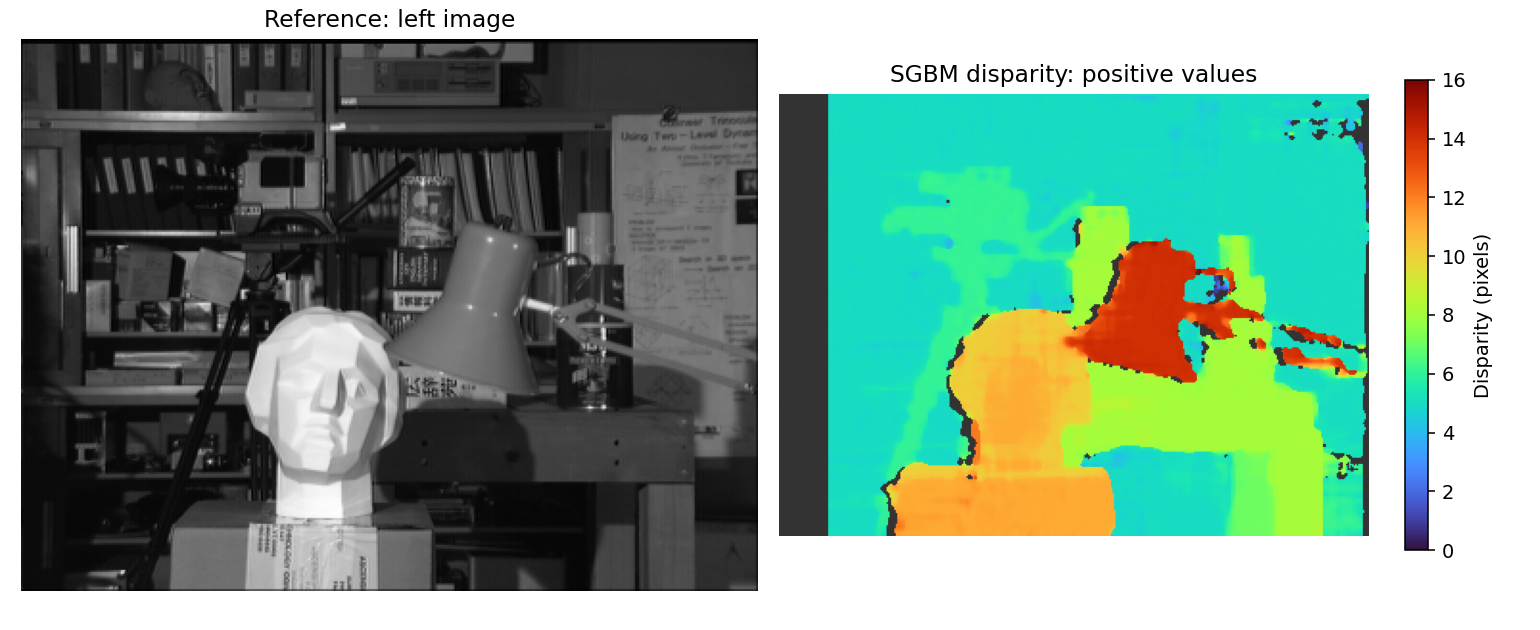

In [5]:
# 셀 5: SGBM의 왼쪽 기준 시차를 계산한다.
MIN_DISPARITY = 0
NUM_DISPARITIES = 32
BLOCK_SIZE = 5
assert NUM_DISPARITIES > 0 and NUM_DISPARITIES % 16 == 0
assert BLOCK_SIZE >= 1 and BLOCK_SIZE % 2 == 1

def make_matcher(min_disparity):
    # 그레이스케일 입력이므로 채널 수 1에 맞춘 시차 변화 벌점을 사용한다.
    return cv2.StereoSGBM_create(
        minDisparity=min_disparity, numDisparities=NUM_DISPARITIES,
        blockSize=BLOCK_SIZE, P1=8 * BLOCK_SIZE**2, P2=32 * BLOCK_SIZE**2,
        uniquenessRatio=10, speckleWindowSize=50, speckleRange=2,
        disp12MaxDiff=1, preFilterCap=31, mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)

matcher_l = make_matcher(MIN_DISPARITY)
raw_l = matcher_l.compute(rect_l, rect_r)
# 1/16픽셀 단위 정수를 실제 픽셀 단위 float32로 바꾼다.
disp_l = raw_l.astype(np.float32) / 16.0
valid_l = (raw_l > (MIN_DISPARITY - 1) * 16) & (disp_l > 0)
if not np.any(valid_l):
    raise RuntimeError('양의 시차가 없습니다. 좌우 순서와 탐색 범위를 확인하세요.')

# 시각화 상한은 계산값을 읽기 쉽게 올림한 것이며 검색 범위를 바꾸지 않는다.
view_max = float(np.ceil(np.max(disp_l[valid_l])))
disp_cmap = plt.get_cmap('turbo').copy()
disp_cmap.set_bad('#333333')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].imshow(rect_l, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Reference: left image')
im = axes[1].imshow(np.where(valid_l, disp_l, np.nan), cmap=disp_cmap,
                    vmin=0, vmax=view_max)
axes[1].set_title('SGBM disparity: positive values')
for ax in axes:
    ax.axis('off')
fig.colorbar(im, ax=axes[1], label='Disparity (pixels)', shrink=0.8)
print(f'양의 시차를 가진 픽셀 비율: {valid_l.mean():.2%}')
finish(fig, '03_disparity_raw.png')

### 좌우 일관성 검사

왼쪽에서 찾은 대응을 오른쪽에서 거꾸로 찾아도 원래 위치와 비슷해야 한다.

$$x_R=x_L-d_L(x_L,y)$$

오른쪽 기준 시차는 부호가 반대인 $d_R=x_R-x_L$로 정의한다. 따라서 다음 값이 작아야 한다.

$$e_{LR}(x_L,y)=|d_L(x_L,y)+d_R(x_R,y)|$$

- 이번 구현은 $x_R$를 가까운 정수 픽셀로 반올림하여 오른쪽 시차를 읽는다.
- 화면 밖 대응, 무효 오른쪽 시차, $e_{LR}>1$픽셀인 위치는 제외한다.
- 왼쪽 탐색은 0~31, 반대 방향은 −31~0에 대응하도록 설정한다.
- 이 검사를 통과해도 반복 무늬 등에서 양쪽이 같은 잘못된 대응을 고를 수 있다.
- **통과 픽셀 비율은 정답률이 아니다.** 제외 영역을 메워서 측정된 깊이처럼 표시하지 않는다.

### 셀 6. 반대 방향 계산과 불확실한 영역 표시

전체 픽셀 중 검사 통과 비율: 81.99% — 정확도 점수가 아님


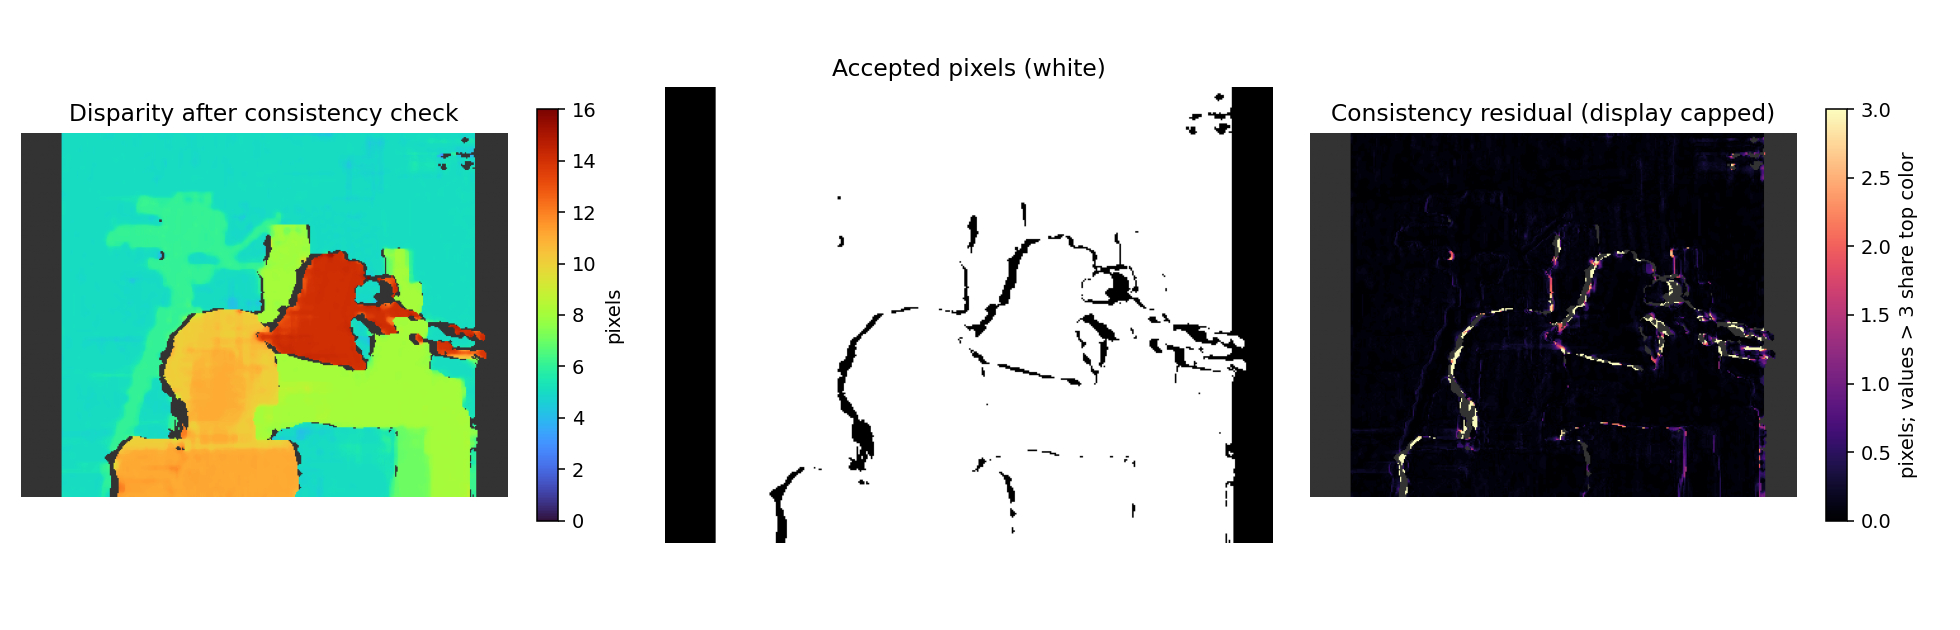

In [6]:
# 셀 6: 오른쪽 기준 시차를 별도로 구하고 좌우 일관성을 확인한다.
MIN_DISPARITY_R = -MIN_DISPARITY - NUM_DISPARITIES + 1
matcher_r = make_matcher(MIN_DISPARITY_R)
raw_r = matcher_r.compute(rect_r, rect_l)
disp_r = raw_r.astype(np.float32) / 16.0

# 왼쪽 픽셀이 가리키는 오른쪽 x좌표를 구한다.
yy, xx = np.indices(disp_l.shape)
xr = np.rint(xx - disp_l).astype(np.int32)
inside = (xr >= 0) & (xr < width)
xr_safe = np.clip(xr, 0, width - 1)  # 배열 접근용 제한이며 유효 판정에는 inside도 필요하다.
sampled_r = disp_r[yy, xr_safe]
valid_r_at_match = (raw_r[yy, xr_safe] > (MIN_DISPARITY_R - 1) * 16) & (sampled_r <= 0)
lr_error = np.abs(disp_l + sampled_r)
LR_THRESHOLD = 1.0
valid = valid_l & inside & valid_r_at_match & (lr_error <= LR_THRESHOLD)
if not valid.any():
    raise RuntimeError('좌우 일관성 검사를 통과한 픽셀이 없습니다.')
disparity = np.where(valid, disp_l, np.nan).astype(np.float32)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
im = axes[0].imshow(disparity, cmap=disp_cmap, vmin=0, vmax=view_max)
axes[0].set_title('Disparity after consistency check')
fig.colorbar(im, ax=axes[0], label='pixels', shrink=0.7)
axes[1].imshow(valid, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Accepted pixels (white)')
error_view = np.where(valid_l & inside & valid_r_at_match, lr_error, np.nan)
err_cmap = plt.get_cmap('magma').copy()
err_cmap.set_bad('#333333')
im = axes[2].imshow(error_view, cmap=err_cmap, vmin=0, vmax=3)
axes[2].set_title('Consistency residual (display capped)')
fig.colorbar(im, ax=axes[2], label='pixels; values > 3 share top color', shrink=0.7)
for ax in axes:
    ax.axis('off')
print(f'전체 픽셀 중 검사 통과 비율: {valid.mean():.2%} — 정확도 점수가 아님')
finish(fig, '04_consistency.png')

## 9.5 깊이 추정

### 시차와 미터 단위 깊이는 다르다

정렬된 수평 스테레오에서 두 주점의 x좌표 차이가 있으면 유효 시차는 다음과 같다.

$$d_{\mathrm{eff}}=d-(c_{xL}-c_{xR}),\qquad Z=\frac{fB}{d_{\mathrm{eff}}}$$

- 이번 첨부 파일에는 검증된 $f$, $B$, $c_{xL}-c_{xR}$가 없다.
- 따라서 결과 그림을 실제 거리(m)라고 표시하지 않는다.
- **주점 차이가 0이라고 가정**하고, 시차의 역수를 비교하는 상대 지표를 만든다.
- 기준 시차 $d_{ref}$는 일관성 검사를 통과한 시차의 중앙값으로 정한다.

$$Z_{index}=\frac{d_{ref}}{d}$$

- 지표가 작으면 상대적으로 가까운 쪽, 크면 먼 쪽으로 해석한다.
- 이 가정이 성립하면 깊이의 비율로 연결할 수 있지만, 현재 영상의 실측 깊이비가 검증된 것은 아니다.
- 표시용 정규화된 그림과 픽셀 단위 시차 배열을 혼동하지 않는다.

### 셀 7. 상대 깊이 지표와 수동 선택 영역 비교

머리·책장·스탠드 부근의 사각형은 설명을 위해 직접 정했다. 물체를 자동 검출하거나 분할한 결과가 아니다. 같은 사각형에서도 깊이가 섞일 수 있으므로 통과 픽셀의 중앙값을 비교한다.

| 선택 영역 | 통과 픽셀 비율 | 시차 중앙값(px) | 상대 깊이 지표 중앙값 |
| :---: | :---: | :---: | :---: |
| 머리 부근 | 98.29% | 10.812 | 0.474 |
| 배경 책장 | 100.00% | 5.000 | 1.025 |
| 스탠드 부근 | 97.90% | 14.000 | 0.366 |


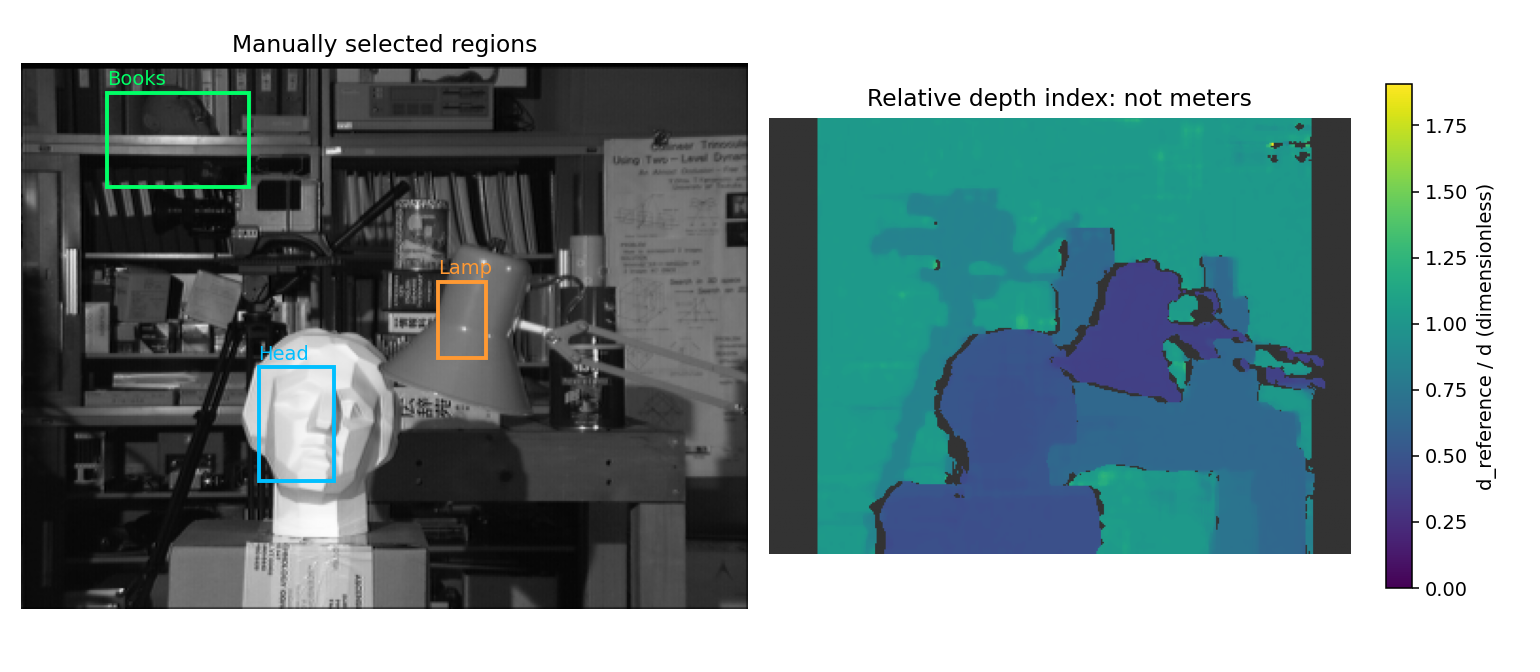

In [7]:
# 셀 7: 보정값을 가정해 미터 단위로 바꾸지 않고 상대 깊이 지표를 계산한다.
reference_disparity = float(np.median(disparity[valid]))
relative_depth_index = np.full(disparity.shape, np.nan, np.float32)
# 아래 지표는 주점 x좌표 차이가 0이라는 가정 아래 시차 역수를 비교한다.
relative_depth_index[valid] = reference_disparity / disparity[valid]

# 좌표는 (x0, y0, x1, y1)이며 끝 좌표는 포함하지 않는다. 사람이 직접 고른 영역이다.
regions = [
    ('Head', '머리 부근', (125, 160, 165, 220), '#00bfff'),
    ('Books', '배경 책장', (45, 15, 120, 65), '#00ff66'),
    ('Lamp', '스탠드 부근', (220, 115, 245, 155), '#ff9933'),
]
roi_rows = []
for name, label, (x0, y0, x1, y1), color in regions:
    mask_roi = valid[y0:y1, x0:x1]
    values = disparity[y0:y1, x0:x1][mask_roi]
    median_d = float(np.median(values)) if values.size else None
    median_index = float(np.median(relative_depth_index[y0:y1, x0:x1][mask_roi])) if values.size else None
    roi_rows.append(dict(region=name, label=label, x0=x0, y0=y0, x1=x1, y1=y1,
                         valid_fraction=float(mask_roi.mean()), median_disparity_px=median_d,
                         median_relative_depth_index=median_index))

table = '| 선택 영역 | 통과 픽셀 비율 | 시차 중앙값(px) | 상대 깊이 지표 중앙값 |\n'
table += '| :---: | :---: | :---: | :---: |\n'
for row in roi_rows:
    d = '계산 불가' if row['median_disparity_px'] is None else f"{row['median_disparity_px']:.3f}"
    z = '계산 불가' if row['median_relative_depth_index'] is None else f"{row['median_relative_depth_index']:.3f}"
    table += f"| {row['label']} | {row['valid_fraction']:.2%} | {d} | {z} |\n"
display(Markdown(table))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
axes[0].imshow(rect_l, cmap='gray', vmin=0, vmax=255)
for name, label, (x0, y0, x1, y1), color in regions:
    axes[0].add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0, fill=False, edgecolor=color, linewidth=2))
    axes[0].text(x0, y0-4, name, color=color, fontsize=10)
axes[0].set_title('Manually selected regions')
z_cmap = plt.get_cmap('viridis').copy()
z_cmap.set_bad('#333333')
im = axes[1].imshow(relative_depth_index, cmap=z_cmap,
                    vmin=0, vmax=float(np.nanmax(relative_depth_index)))
axes[1].set_title('Relative depth index: not meters')
fig.colorbar(im, ax=axes[1], label='d_reference / d (dimensionless)', shrink=0.8)
for ax in axes:
    ax.axis('off')
finish(fig, '05_relative_depth.png')

### 보정값을 확보했을 때의 깊이 계산

- 아래 함수에는 **정렬 후** 초점거리, 베이스라인, 좌우 주점 차이를 입력한다.
- 다른 해상도나 다른 카메라의 값을 넣으면 안 된다.
- $Q$를 확보했다면 픽셀 단위 float 시차에 `cv2.reprojectImageTo3D()`를 적용할 수 있다. 16배 원시 정수를 그대로 전달하지 않는다.
- 무효 시차는 마스크로 제외하고, 계산할 수 없는 깊이는 NaN으로 유지한다.

초점거리·베이스라인·주점을 고정하고 작은 시차 오차만 고려하면:

$$|\Delta Z|\approx\frac{fB}{d_{\mathrm{eff}}^2}|\Delta d|$$

유효 시차가 작을수록 같은 시차 오차가 더 큰 깊이 오차로 이어진다. 보정값 자체의 오차는 이 식에 별도로 포함되지 않는다.

### 셀 8. 미터 깊이 함수 정의와 실제 계산 배열 저장

미터 깊이 함수는 **정의만 하며 현재 Tsukuba에 호출하지 않는다.** 저장 배열에는 실제 계산한 시차·마스크·상대 지표를 넣는다. 정답 시차가 없으므로 MAE, RMSE, 정확도는 계산하지 않는다.

In [8]:
# 셀 8: 실제 보정값이 있을 때만 사용하는 깊이 함수와 현재 실습 결과를 저장한다.
def metric_depth_from_calibration(disparity_px, valid_mask, focal_px, baseline_m, cx_offset_px):
    # baseline_m을 미터로 넣었을 때 출력도 미터가 된다. 외부에서 확인한 값을 전달한다.
    parameters = np.asarray([focal_px, baseline_m, cx_offset_px], dtype=np.float64)
    if not np.all(np.isfinite(parameters)) or focal_px <= 0 or baseline_m <= 0:
        raise ValueError('유효한 초점거리·베이스라인·주점 차이가 필요합니다.')
    if disparity_px.shape != valid_mask.shape:
        raise ValueError('시차와 마스크의 크기가 다릅니다.')
    d_eff = np.asarray(disparity_px, np.float32) - float(cx_offset_px)
    valid_depth = np.asarray(valid_mask, bool) & np.isfinite(d_eff) & (d_eff > 0)
    depth_m = np.full(d_eff.shape, np.nan, np.float32)
    depth_m[valid_depth] = float(focal_px) * float(baseline_m) / d_eff[valid_depth]
    return depth_m, valid_depth

# 원본 파일 해시를 기록해 어떤 좌우 입력을 계산했는지 구분한다.
input_hashes = {name: hashlib.sha256((ASSETS/name).read_bytes()).hexdigest()
                for name in ['tsukuba_l.png', 'tsukuba_r.png']}
results = {
    'python': platform.python_version(), 'opencv': cv2.__version__, 'numpy': np.__version__,
    'input_pair': 'user-provided Tsukuba', 'image_size_wh': [width, height],
    'input_sha256': input_hashes, 'rectification_assumed': True,
    'calibration_performed': False, 'calibration_parameters_provided': False,
    'ground_truth_available': False, 'metric_depth_computed': False,
    'relative_index_assumption_cx_difference_px': 0.0,
    'matcher': {'min_disparity_left': MIN_DISPARITY, 'min_disparity_right': MIN_DISPARITY_R,
                'num_disparities': NUM_DISPARITIES, 'block_size': BLOCK_SIZE,
                'lr_threshold_px': LR_THRESHOLD, 'mode': 'SGBM_3WAY'},
    'alignment_diagnostic': alignment,
    'positive_disparity_fraction': float(valid_l.mean()),
    'consistency_pass_fraction': float(valid.mean()),
    'accepted_disparity_min_px': float(np.min(disparity[valid])),
    'accepted_disparity_max_px': float(np.max(disparity[valid])),
    'reference_disparity_px': reference_disparity,
    'manual_regions': roi_rows,
}
# PNG는 표시용이며, 재분석에는 NaN과 부호를 보존한 NPZ 배열을 사용한다.
np.savez_compressed(ROOT/'stereo_results.npz', left=rect_l, right=rect_r,
    disparity_left_raw=raw_l, disparity_right_raw=raw_r,
    disparity_left_px=disp_l, disparity_right_px=disp_r,
    disparity_accepted_px=disparity, positive_mask=valid_l, consistent_mask=valid,
    lr_error_px=lr_error, relative_depth_index=relative_depth_index)
(ROOT/'results.json').write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding='utf-8')
with (ROOT/'roi_summary.csv').open('w', encoding='utf-8-sig', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=list(roi_rows[0]))
    writer.writeheader()
    writer.writerows(roi_rows)

# 계산 구조를 확인한다. 정답 시차와 비교하는 정확도 검사는 아니다.
assert raw_l.dtype == np.int16 and disparity.shape == left.shape
assert np.all(np.isfinite(disparity[valid])) and np.all(disparity[valid] > 0)
assert np.isnan(disparity[~valid]).all()
assert np.all(lr_error[valid] <= LR_THRESHOLD)
assert np.allclose(relative_depth_index[valid] * disparity[valid], reference_disparity)
print('저장 완료: results.json, stereo_results.npz, roi_summary.csv')
print('미터 단위 깊이: 계산하지 않음 / 정답 대비 오차: 계산하지 않음')

저장 완료: results.json, stereo_results.npz, roi_summary.csv
미터 단위 깊이: 계산하지 않음 / 정답 대비 오차: 계산하지 않음


## 실제 실행 결과 해석

- 입력 크기: **384×288**, OpenCV **5.0.0**.
- 비율 검사를 통과한 특징점 대응: **686쌍**. 세로 차이의 중앙값은 **0.000픽셀**, 90백분위수는 **1.610픽셀**이다.
- 좌우 일관성 검사 통과 비율: 전체 영상의 **81.99%**. 이는 유효 영역의 비율이며 정답률이 아니다.
- 통과한 시차 범위: **2.6875~15.8125픽셀**.
- 수동 선택한 머리 부근의 시차 중앙값은 **10.812픽셀**, 배경 책장은 **5.000픽셀**이다. 이 영상 쌍의 가정 아래 머리 부근이 책장보다 가까운 방향으로 해석된다.
- 그림의 짙은 회색은 계산에서 제외한 위치다. 검은 물체나 무한히 먼 배경이라는 뜻이 아니다.
- 물체 가장자리의 가림, 책장의 반복 무늬, 균일한 면, 밝기가 낮은 곳에서는 추정이 불안정할 수 있다. 일관성 검사만으로 모든 오대응을 없앨 수는 없다.

## 실행 검증 범위

- 8개 코드 셀을 **하나의 Python/IPython 실행 상태에서 순차 실행**하여 출력과 PNG를 기록했다.
- 시차 계산·역방향 계산·일관성 검사·상대 지표 계산과 저장을 실제 수행했다.
- 보정·보정값 기반 정렬·미터 깊이 함수는 정의만 했으며, 미제공 관측값이나 보정값으로 실행한 결과가 아니다.
- Jupyter TCP 커널은 환경에서 `Operation not permitted`로 시작하지 못했다. 실제 Jupyter 커널의 Run All 검증과 구분한다.

## 참고 문서

- [OpenCV — StereoSGBM](https://docs.opencv.org/4.x/d2/d85/classcv_1_1StereoSGBM.html)
- [OpenCV — Camera Calibration and 3D Reconstruction](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html)
- [Middlebury — 2001 Stereo Datasets / Tsukuba 안내](https://vision.middlebury.edu/stereo/data/scenes2001/)

입력 이미지는 사용자가 첨부한 두 PNG를 그대로 사용했다. 위 데이터셋 링크는 배경 설명을 위한 참고이며, 별도 원본·보정값·정답 시차를 내려받아 대체하거나 정확도를 평가한 것은 아니다.
